In [22]:
import numpy as np 
import matplotlib.pyplot as plt
from hcipy import *
import os
import sys

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [23]:
#importing the onsky filtered field cube
fields = read_field('/Users/Katie/Documents/Fall 2023/MagAO-X/ADC Sim code/updated onsky/all_filtered_fields.fits')

In [34]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+2*std) & (data > mean-2*std))
    return data[indices]

In [25]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [26]:
#now doing calculations for the cube, but cutting it off near the beginning because that's all we need
fields_trimmed = fields[0:2000]

ADC.set_control_mtx(np.array([0.21178766, 0.19275196]))
disps = np.zeros(len(fields_trimmed))
commands = []
speckle_angles = []
pointings = []

for i, field in enumerate(fields_trimmed):
    ADC.set_psf(field)
    angles = ADC.find_speckle_angles2()
    pairs = ADC.speckle_pairs(angles)
    speckle_angles.append(angles)
    pointings.append(pairs)
    commands.append(ADC.calculate_command(pairs))

pointings = np.array(pointings)
commands = np.array(commands)

In [30]:
print(len(commands))
print(len(pointings))

2000
2000


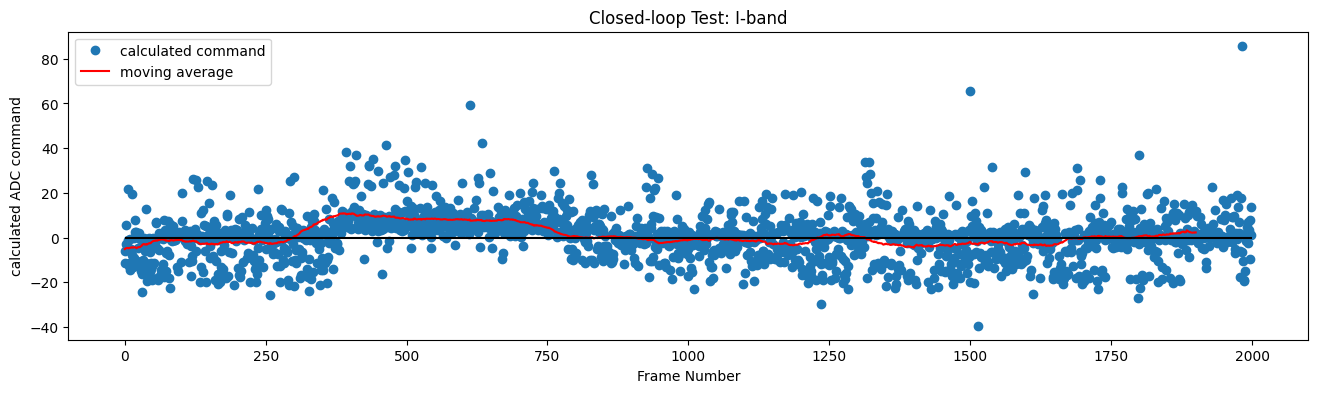

In [31]:
avg = moving_average(commands,n=100)

plt.figure(figsize=(16,4))
plt.plot(np.squeeze(commands),'o',label='calculated command')
plt.plot(avg,'-',label='moving average',color='red')
plt.hlines(0,0,len(commands),'black')
plt.xlabel('Frame Number')
plt.ylabel('calculated ADC command')
plt.title('Closed-loop Test: I-band')
plt.legend()

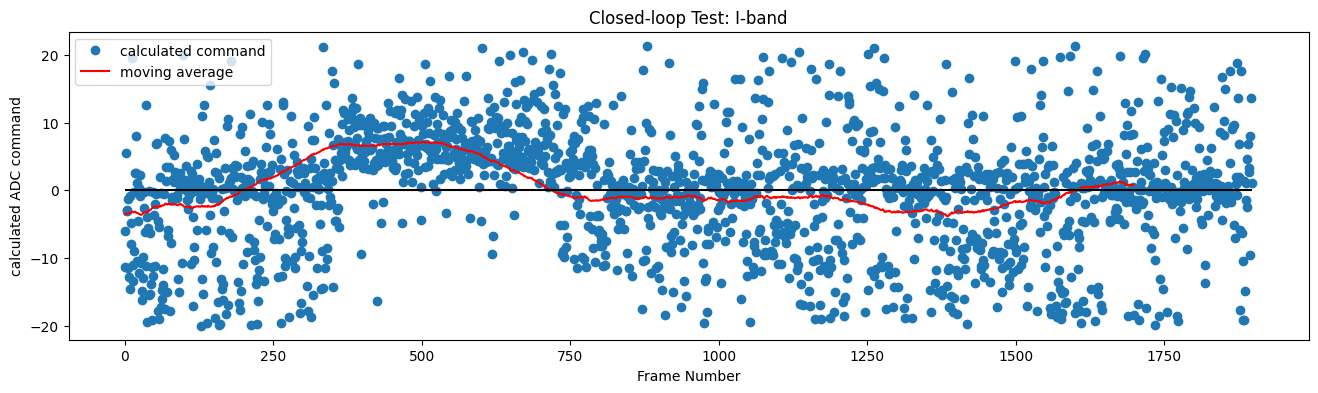

In [35]:
all_commands = reject_outliers(np.squeeze(commands))
avg = moving_average(all_commands,n=200)

plt.figure(figsize=(16,4))
plt.plot(np.squeeze(all_commands),'o',label='calculated command')
plt.plot(avg,'-',label='moving average',color='red')
plt.hlines(0,0,len(all_commands),'black')
plt.xlabel('Frame Number')
plt.ylabel('calculated ADC command')
plt.title('Closed-loop Test: I-band')
plt.legend()

In [ ]:
print(avg[500])
#so yeah, definitely the wrong response matrix. but I can try and do what i want with this data and then figure out which response matrix is the correct one at the end


7.128178769973962
